# Analysis 1.A — Treasury curve conditions and movements

Inspect 2Y/10Y/30Y Treasury yields and compare exact endpoints. Yield levels are percent; spread levels and all changes are basis points. Start Jupyter from the repository root with `poetry run jupyter lab` after `poetry install`, using the Poetry Python kernel.

Execute **A → B → C → D** manually. After changing either DatePicker, rerun C to redraw the selected period and D to recalculate; each reads the widgets independently. Zoom, pan and the range slider inspect the history without changing selected analysis dates. No automatic callbacks are installed.

`download` retrieves and saves one self-contained CSV with comment-header provenance. The key order is explicit Python argument → `FRED_API_KEY` environment variable → root `.env`; without a key, the three known H.15 series use FRED's public CSV. `file` reads the selected CSV offline. Old JSON caches must be downloaded again or converted explicitly; see [README](README.md).

In [1]:
from pathlib import Path
import ipywidgets as widgets
from IPython.display import display

from bondview.data.fred import FredDataManager
from bondview.analysis.treasury_curve import analyze_curve
from bondview.plotting.treasury_curve import show_yield_history
from bondview.presentation.treasury_curve import show_curve_results
from bondview.presentation.widgets import DateRangePicker

# Set the repository root explicitly if starting Jupyter outside the project.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data/fred/treasury_yields.csv"

## A. Load FRED data

This is the only step that can contact FRED. Missing observations remain missing; the manager retains provenance independently of DataFrame attributes.

In [5]:
DATA_MODE = "file" # "download" or "file"
start = '2000-01-01'
end = None
fred = FredDataManager(DATA_PATH, env_path=PROJECT_ROOT / ".env")
observations = fred.load_or_download(DATA_MODE, start=start, end=end)
fred.report()

FRED / Federal Reserve H.15 | Retrieved: 2026-10-26T11:02:46.425982+00:00
Loaded coverage: 2000-01-03 to 2026-10-22 | 6994 rows | /home/lbk/works/bondview-v3/data/fred/treasury_yields.csv
DGS2: Percent, D; missing: 289
DGS10: Percent, D; missing: 289
DGS30: Percent, D; missing: 289
Retrieval-time snapshot; historical data availability at the observation date is not reconstructed.


In [6]:
# Initialize the date range picker
date_range = DateRangePicker(observations)

## B. Select dates

Initial values use the loaded date coverage. Dates are exact: weekends, holidays and out-of-coverage dates may produce `N/A`. Changing a widget changes the next execution's inputs; it does not automatically refresh existing outputs. Rerunning B resets the widgets to loaded coverage.

## C. Draw Treasury yield history — run manually

Both selected widget dates set this figure's initial visible range. Full loaded history remains available through normal Plotly interactions. Missing observations remain gaps.

In [7]:
date_range

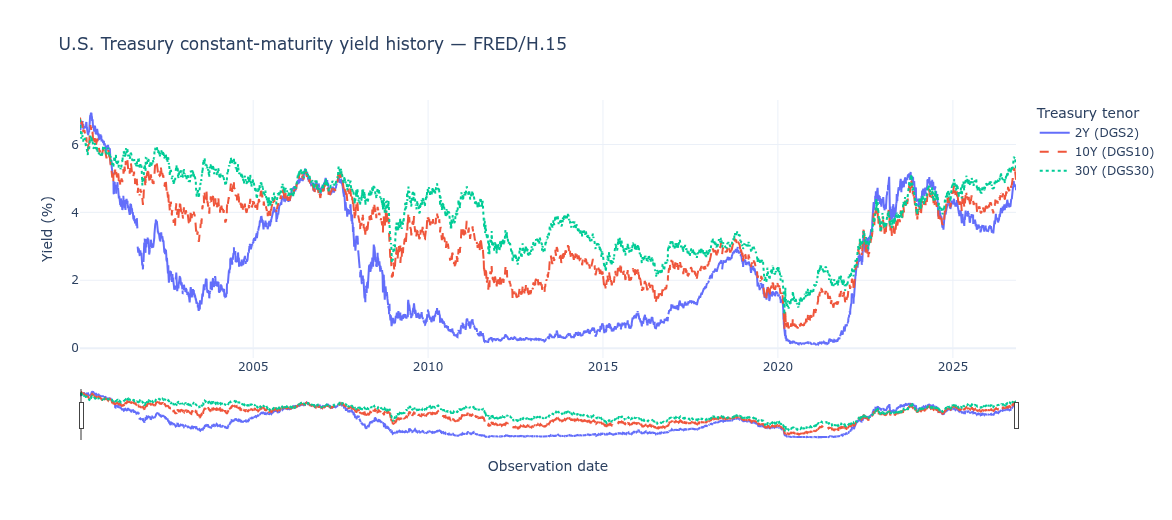

In [10]:
history_figure = show_yield_history(
    observations, *date_range.get_dates()
)

## D. Calculate and display Analysis 1.A — run manually

Each segment uses `Δslope = Δlong − Δshort`. The nonnegative `slope_tolerance_bp` applies inclusively only to slope changes; its Python default is zero. Yield directions use actual signs. Unequal changes never become parallel shifts; stationary tenors are stated explicitly. Opposing-direction twist is a descriptive convention, not a universal taxonomy.

Configurations use the signs of endpoint spreads. Available endpoints survive missing dependent changes; no nearby observation substitutes for a missing date. The five-row structured result uses stable IDs; presentation terminology comes from `config/labels.yaml`.

The design example interval 2024-09-16 → 2025-01-13 has yield changes +84/+116/+103 bp and spread changes +32/−13 bp. Loaded observations determine these results; agreement is never forced. This is net historical Treasury-tenor analysis, not a forecast, ETF return, or recommendation. Retrieval snapshots do not reconstruct historical release availability.

In [9]:
result = analyze_curve(
    observations, *date_range.get_dates(),
    slope_tolerance_bp=0,
)
show_curve_results(result)

,2000-01-03,End 2026-10-22,Change,Curve configuration,Movement / regime
Treasury measure,,,,,
2Y yield,6.38%,4.65%,-173.00 bp,—,Yield fell
10Y yield,6.58%,4.96%,-162.00 bp,—,Yield fell
30Y yield,6.61%,5.29%,-132.00 bp,—,Yield fell
10Y−2Y spread,+20.00 bp,+31.00 bp,+11.00 bp,Upward-sloping → Upward-sloping,Bull steepening
30Y−10Y spread,+3.00 bp,+33.00 bp,+30.00 bp,Upward-sloping → Upward-sloping,Bull steepening


Greatest downward yield movement among available tenors: 2Y (-173.00 bp). 10Y−2Y spread: Bull steepening. 30Y−10Y spread: Bull steepening. These are net endpoint movements, not the full path or a forecast. ETF rate-price effects depend on duration and other product characteristics.